# IND320 — Dashboard basics

Reservoir data analysis for the first compulsory hand-in. The source file is the course's `D2Dbook/data/reservoirs.csv`.

## Project links

- Public GitHub repository: https://github.com/yaksh-git/ind320-dashboard-basics-yaksh-git
- Streamlit app: https://ind320-dashboard-basics-yaksh-git.streamlit.app/

## 1. Load and rename the data

The source contains nine geographic series for each reporting week. For line plots, this notebook uses the supplied Norway total (`NO`, area `0`) so that each line represents one consistent area. The full imported data remains available in `data`.

In [1]:
from pathlib import Path
import os
import pandas as pd
# Use a writable project cache before importing Matplotlib on Windows.
mpl_cache = Path('.matplotlib')
mpl_cache.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(mpl_cache.resolve())
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook', palette='deep')

# Keep the CSV in the same folder as this notebook.
csv_path = Path('reservoirs.csv')
data = pd.read_csv(csv_path)

# Translate all source headers once; use these names in later cells.
column_names = {
    'dato_Id': 'date',
    'omrType': 'area_type',
    'omrnr': 'area_number',
    'iso_aar': 'iso_year',
    'iso_uke': 'iso_week',
    'fyllingsgrad': 'fill_level',
    'kapasitet_TWh': 'capacity_twh',
    'fylling_TWh': 'stored_energy_twh',
    'neste_Publiseringsdato': 'next_publication_date',
    'fyllingsgrad_forrige_uke': 'previous_week_fill_level',
    'endring_fyllingsgrad': 'fill_level_change',
}
data = data.rename(columns=column_names)
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data = data.sort_values(['date', 'area_type', 'area_number']).reset_index(drop=True)
national = data.loc[(data['area_type'] == 'NO') & (data['area_number'] == 0)].copy()
print(f'{len(data):,} rows, {len(data.columns)} columns')
print(f'{national.date.min():%Y-%m-%d} to {national.date.max():%Y-%m-%d}')

14,877 rows, 11 columns
1995-01-08 to 2026-09-06


## 2. Inspect the contents

Show representative rows, column types, missing values and numeric summaries. This is more useful than printing all 14,877 rows.

In [2]:
# Show useful fields from the beginning and end of the sorted source.
preview_columns = ['date', 'area_type', 'area_number', 'fill_level',
                   'capacity_twh', 'stored_energy_twh']
display(data[preview_columns].head(10))
display(data[preview_columns].tail(10))
display(pd.DataFrame({'dtype': data.dtypes.astype(str), 'missing': data.isna().sum()}))
# A compact numeric summary fits both the notebook and PDF page.
display(data.select_dtypes(include='number').describe().T[['count', 'mean', 'std', 'min', 'max']])

,date,area_type,area_number,fill_level,capacity_twh,stored_energy_twh
0,1995-01-08,EL,1,0.621467,6.003264,3.730831
1,1995-01-08,EL,2,0.630947,34.043590,21.479713
2,1995-01-08,EL,3,0.602376,8.920932,5.373754
3,1995-01-08,EL,4,0.558864,21.079208,11.780413
4,1995-01-08,EL,5,0.616448,17.390587,10.720388
5,1995-01-08,NO,0,0.608274,87.437580,53.185986
6,1995-01-08,VASS,1,0.636038,36.044464,22.925638
7,1995-01-08,VASS,2,0.608856,23.237715,14.148431
8,1995-01-08,VASS,3,0.566906,28.155403,15.961480
9,1995-01-15,EL,1,0.583100,6.003264,3.500502


,date,area_type,area_number,fill_level,capacity_twh,stored_energy_twh
14867,2026-08-30,VASS,3,0.827718,28.155403,23.304743
14868,2026-09-06,EL,1,0.725045,6.003264,4.352634
14869,2026-09-06,EL,2,0.460863,34.043590,15.689445
14870,2026-09-06,EL,3,0.632579,8.920932,5.643190
14871,2026-09-06,EL,4,0.902762,21.079208,19.029512
14872,2026-09-06,EL,5,0.638898,17.390587,11.110812
14873,2026-09-06,NO,0,0.636054,87.437580,55.615055
14874,2026-09-06,VASS,1,0.570397,36.044464,20.559645
14875,2026-09-06,VASS,2,0.516978,23.237715,12.013381
14876,2026-09-06,VASS,3,0.826252,28.155403,23.263466


,dtype,missing
date,datetime64[ns],0
area_type,object,0
area_number,int64,0
iso_year,int64,0
iso_week,int64,0
fill_level,float64,0
capacity_twh,float64,0
stored_energy_twh,float64,0
next_publication_date,object,0
previous_week_fill_level,float64,0


,count,mean,std,min,max
area_number,14877.0,2.333333,1.490762,0.000000,5.000000
iso_year,14877.0,2010.346038,9.146696,1995.000000,2026.000000
iso_week,14877.0,26.405929,15.017910,1.000000,53.000000
fill_level,14877.0,0.618852,0.214850,0.055160,1.020072
capacity_twh,14877.0,29.145860,22.739070,6.003264,87.437580
stored_energy_twh,14877.0,18.139713,15.966211,0.331142,84.544820
previous_week_fill_level,14877.0,0.618890,0.214843,0.055160,1.020037
fill_level_change,14877.0,-0.000038,0.031385,-0.242484,0.336623


## 3. Plot every column separately

A time series is a line ordered by date. Reservoir measurements and the ISO year/week fields use this form for the Norway total. The `date` column is already the horizontal coordinate, so its separate chart shows annual reporting frequency (the latest year may be incomplete). Geographic identifiers are categories, so they use count bars. The publication field uses counts of supplied and unavailable dates; year `0001` means no date was supplied.

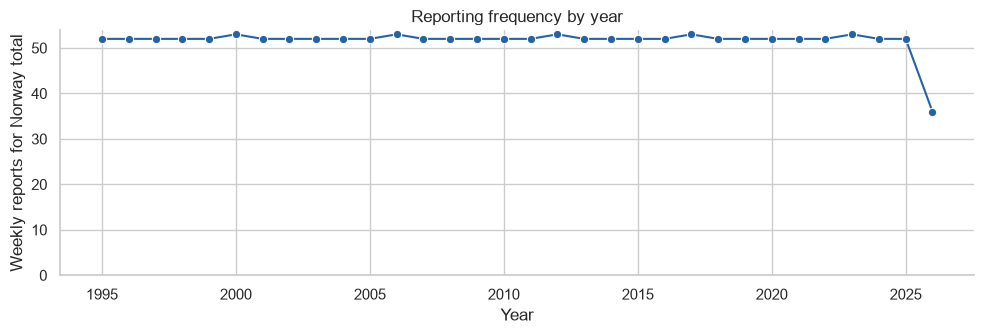

In [3]:
# A date cannot be plotted against itself; count reports in each year.
annual = national.groupby(national['date'].dt.year).size().rename('reports')
annual = annual.rename_axis('year').reset_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.lineplot(data=annual, x='year', y='reports', marker='o',
             color='#2563a6', errorbar=None, ax=ax)
ax.set(title='Reporting frequency by year', xlabel='Year',
       ylabel='Weekly reports for Norway total')
ax.set_ylim(bottom=0)
sns.despine()
fig.tight_layout(); plt.show()

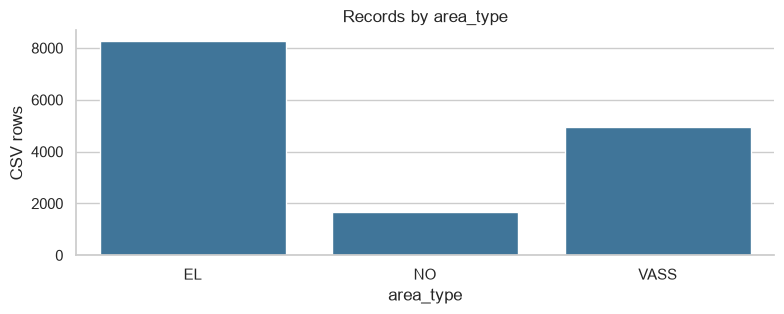

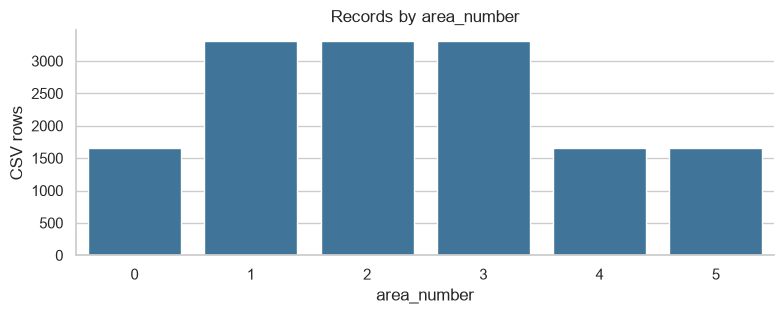

In [4]:
# Area fields are categories, so count their occurrences in all rows.
for column in ['area_type', 'area_number']:
    fig, ax = plt.subplots(figsize=(8, 3.3))
    sns.countplot(data=data, x=column, color='#3178a8', ax=ax)
    ax.set(title=f'Records by {column}', xlabel=column, ylabel='CSV rows')
    sns.despine()
    fig.tight_layout(); plt.show()

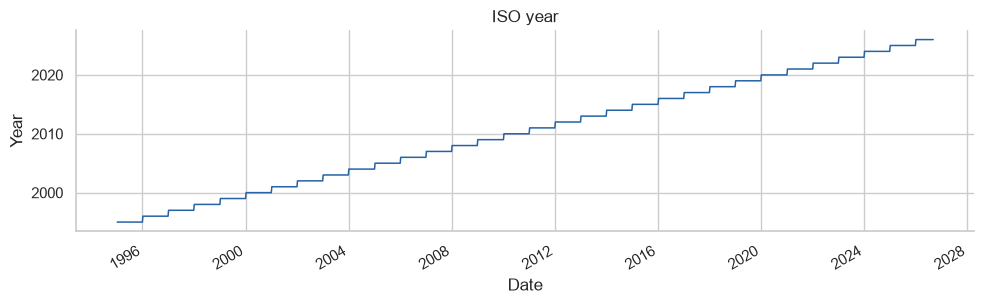

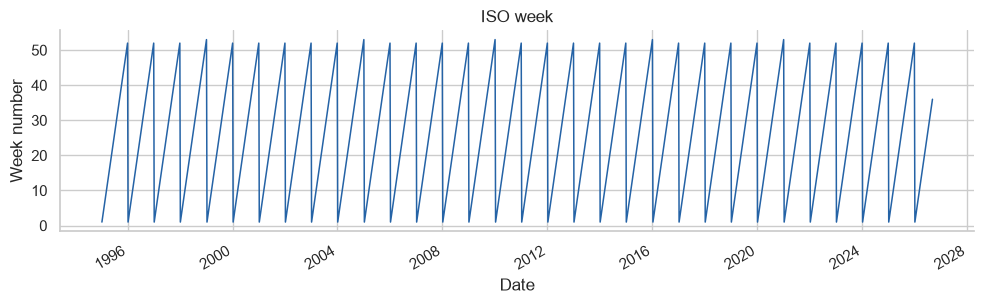

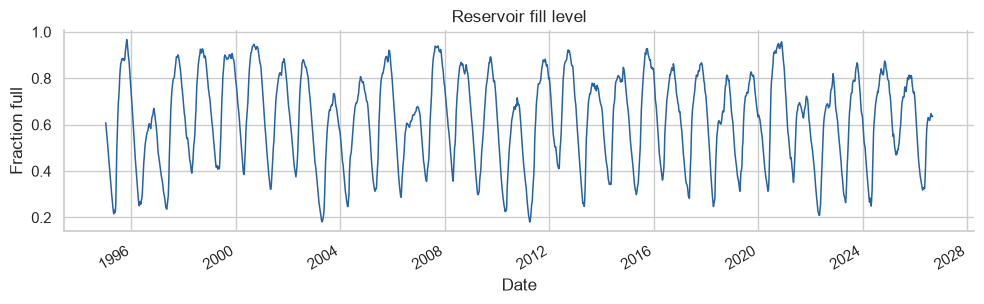

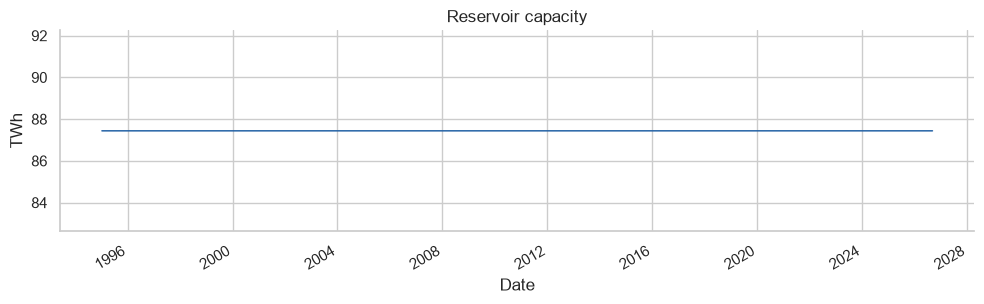

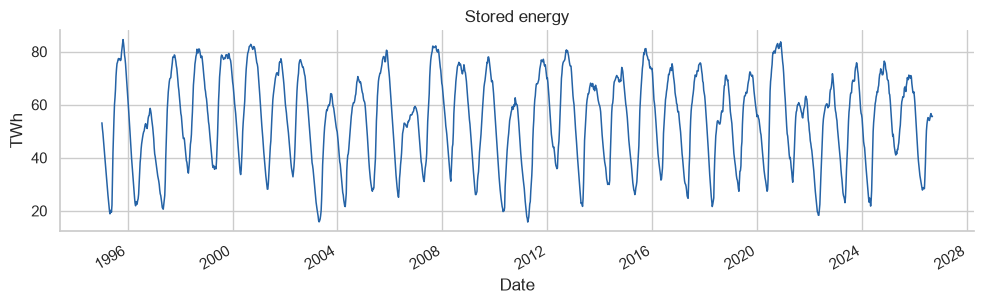

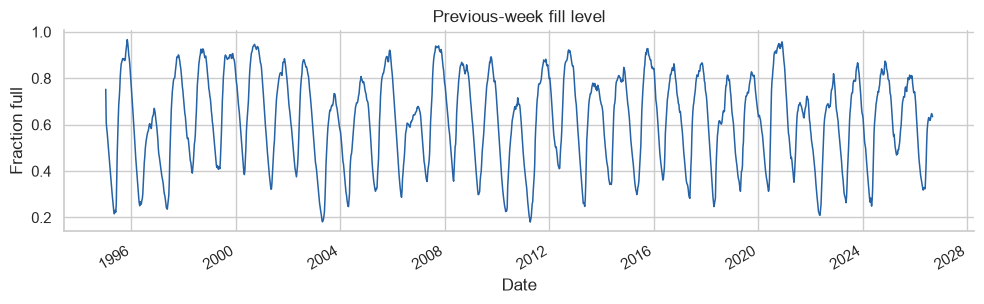

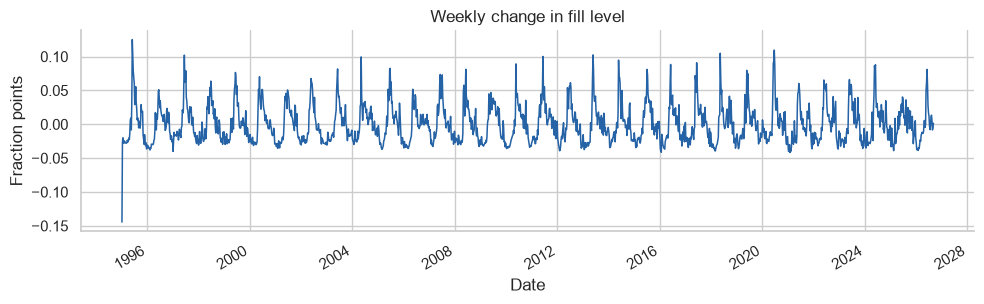

In [5]:
# Each numeric field is a time series for one coherent geographic area.
numeric_columns = ['iso_year', 'iso_week', 'fill_level', 'capacity_twh',
                   'stored_energy_twh', 'previous_week_fill_level', 'fill_level_change']
labels = {'iso_year': ('ISO year', 'Year'),
          'iso_week': ('ISO week', 'Week number'),
          'fill_level': ('Reservoir fill level', 'Fraction full'),
          'capacity_twh': ('Reservoir capacity', 'TWh'),
          'stored_energy_twh': ('Stored energy', 'TWh'),
          'previous_week_fill_level': ('Previous-week fill level', 'Fraction full'),
          'fill_level_change': ('Weekly change in fill level', 'Fraction points')}
for column in numeric_columns:
    fig, ax = plt.subplots(figsize=(10, 3.2))
    sns.lineplot(data=national, x='date', y=column, estimator=None,
                 errorbar=None, color='#2563a6', linewidth=1.1, ax=ax)
    ax.set(title=labels[column][0], xlabel='Date', ylabel=labels[column][1])
    sns.despine()
    fig.autofmt_xdate()
    fig.tight_layout(); plt.show()

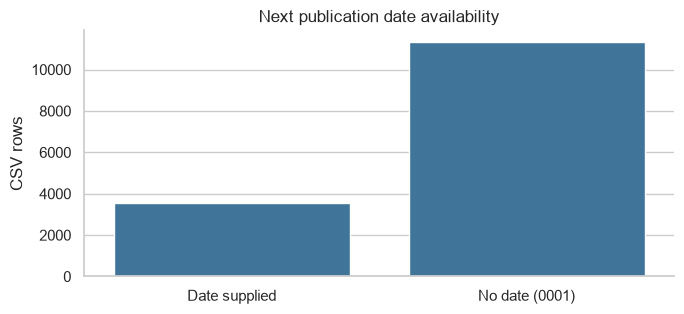

In [6]:
# Year 0001 is outside pandas' datetime range and means no usable date.
next_date = pd.to_datetime(data['next_publication_date'],
                           format='%Y-%m-%dT%H:%M:%S', errors='coerce')
publication_counts = pd.DataFrame({'status': ['Date supplied', 'No date (0001)'],
                                   'rows': [next_date.notna().sum(), next_date.isna().sum()]})
fig, ax = plt.subplots(figsize=(7, 3.3))
sns.barplot(data=publication_counts, x='status', y='rows',
            color='#3178a8', errorbar=None, ax=ax)
ax.set(title='Next publication date availability', xlabel='', ylabel='CSV rows')
sns.despine()
fig.tight_layout(); plt.show()

## 4. Plot all numeric columns together

These seven numeric columns share one figure but have separate panels and vertical scales. This keeps TWh, fractions, years, and week numbers in their original units instead of overlaying unlike quantities. ISO year and week are time identifiers, not reservoir measurements.

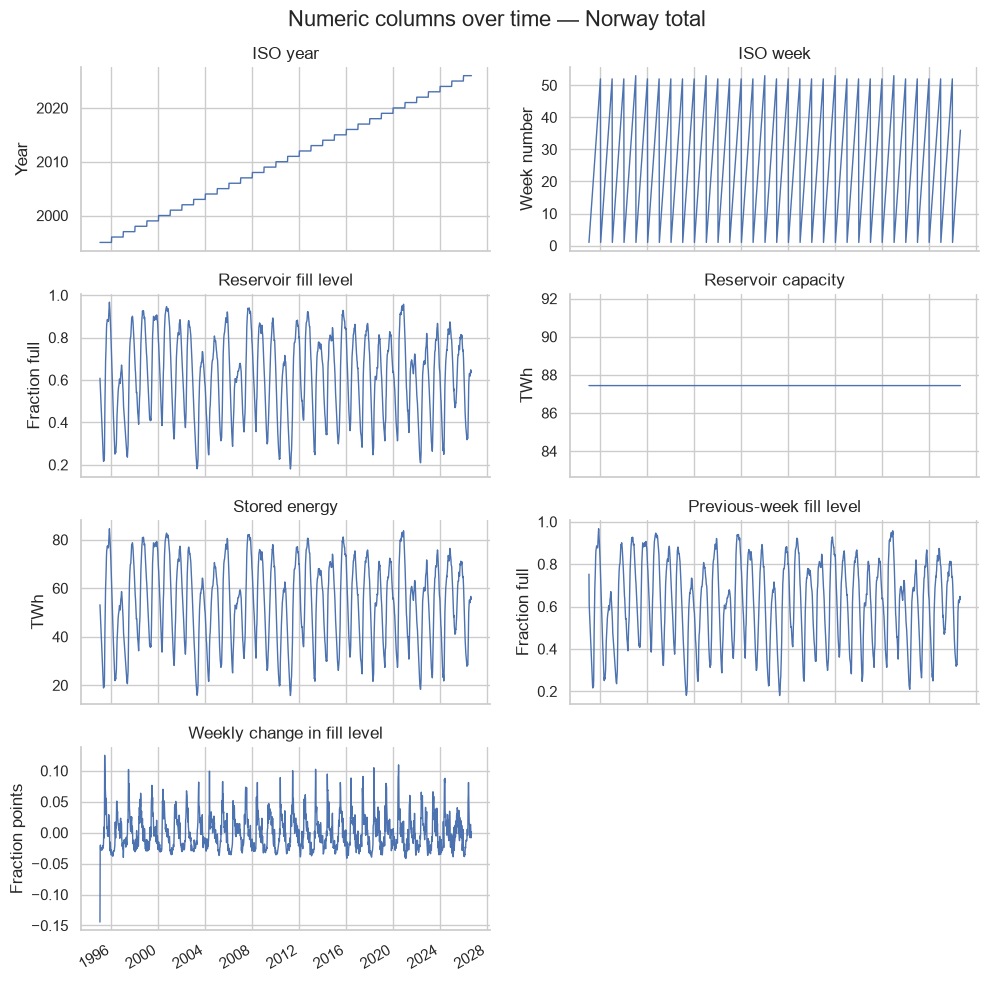

In [7]:
# Small multiples show all numeric fields without mixing their units.
fig, axes = plt.subplots(4, 2, figsize=(10, 10), sharex=True)
for ax, column in zip(axes.flat, numeric_columns):
    sns.lineplot(data=national, x='date', y=column, estimator=None,
                 errorbar=None, linewidth=1, ax=ax)
    ax.set(title=labels[column][0], xlabel='', ylabel=labels[column][1])
    sns.despine(ax=ax)
axes.flat[-1].axis('off')
fig.suptitle('Numeric columns over time — Norway total', fontsize=16)
fig.autofmt_xdate()
fig.tight_layout(); plt.show()

## 5. AI usage

The course encourages the use of AI tools. I chose OpenAI Codex with GPT-6 for this project, although I also have access to Claude Code. I used Codex both to build a first version and to ask how and why the notebook, plots, Streamlit pages, and deployment work. Codex generated most of the initial Python and Streamlit code, notebook structure, comments, and a draft of this log. It also obtained the course CSV, ran checks, set up the public GitHub repository and Streamlit app with my approval, and prepared a PDF for review. I pulled the course repository to my computer and connected Codex to my local project. I asked follow-up questions, inspected outputs, reported warnings, and requested fixes. I explicitly approved the public publication steps rather than enabling automatic approval. I am responsible for checking the final code, results, text, and screencast before submission.

## 6. Work log

I began Part 1 by reading the Canvas instructions and pulling the course repository into a local folder on my computer. I connected Codex to the local project and shared the assignment requirements. The instructions explicitly encourage AI tools, and I wanted to try the GPT-6 models in Codex for this assignment, even though I also have Claude Code. I used AI to explore how the code works and checked whether its output met the requirements. Developers in our company also use AI extensively and review its results manually. In this project, I asked Codex questions about what a Jupyter Notebook is, why it was needed, and how the code and app fit together. Codex generated most of the first implementation, while I guided the task and asked for explanations and corrections.

In the notebook, Pandas reads `reservoirs.csv` and renames the Norwegian headers to English. I can inspect selected rows, data types, missing values, and summary statistics. The CSV contains several geographic areas for each week, so the time series use the supplied Norway total instead of mixing areas. Each column is plotted separately using a suitable form for its data type. Seaborn is used to style the figures and draw the time series. A combined figure uses separate panels and vertical scales for the numeric columns because their units and ranges differ. I ran the cells and looked at the tables and plots. When a date parsing warning appeared, I asked why it happened and had the format specified explicitly. I also reported a Matplotlib cache warning, which led to a writable cache location being configured.

The Streamlit app has four pages. The home page provides sidebar navigation; the data table has one row per imported column and first-month sparklines for numeric values. The plot page lets me select a column or all numeric columns and choose a month range. The fourth page explains the area codes and units and can be extended in later parts. The app reads the local CSV and caches the data. Codex ran local checks of the pages and controls, and I opened the online app to inspect how it behaved. I also collaborated with a fellow student by comparing our plots and discussing why they looked different, especially the variables and scales shown.

I explicitly approved the public GitHub repository and Streamlit publication steps. Codex handled the technical setup, testing, and deployment; I did not enable automatic approval for those public actions. I have continued to ask what and why when reviewing the work. Before submitting, I will check the final notebook and PDF against the assignment and explain the code and my AI use in the screencast.
